# Homework 4 solutions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg

## 1. Time-independent Schrödinger equation

Bound state energy =  -0.35398543103367774


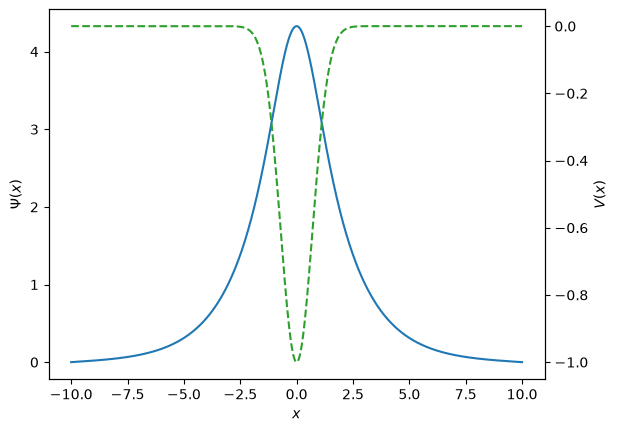

In [3]:
n = 1001
x = np.linspace(-10,10,n)
h = x[1]-x[0]
V = - 1 * np.exp(-x**2)

# Construct the matrix and solve for the first 4 eigenvalues and eigenvectors
A = np.diag(2*np.ones(n) + h**2*V, k=0) + np.diag(-np.ones(n-1),k=-1) + np.diag(-np.ones(n-1),k=1)
E, f = scipy.linalg.eigh(A, subset_by_index=(0,3))

E = E/h**2
for EE in E:
    if EE<0:
        print("Bound state energy = ", EE)

fig, ax1 = plt.subplots()
for i in range(len(E)):
    norm = scipy.integrate.simpson(f[:,i]**2,x)
    if E[i]<0:
        plt.plot(x, f[:, i]/norm)
ax1.set_ylabel(r'$\Psi(x)$')
ax2 = ax1.twinx()
plt.plot(x, V, "C2--")
ax2.set_ylabel(r'$V(x)$')
ax1.set_xlabel(r'$x$')
plt.show()

In [4]:
nvals = (100, 200, 400, 800, 1600)
xvals = (5,10,20)

Earr = np.zeros((len(nvals), len(xvals)))

for j, x0 in enumerate(xvals):
    for i, n1 in enumerate(nvals):
        n = int(n1 * x0/20) + 1
        x = np.linspace(-x0,x0,n)
        h = x[1]-x[0]
        V = - np.exp(-x**2)
        A = np.diag(2*np.ones(n) + h**2*V, k=0) + np.diag(-np.ones(n-1),k=-1) + np.diag(-np.ones(n-1),k=1)
        E = scipy.linalg.eigh(A, subset_by_index=(0,0), eigvals_only=True)   # we only need the first eigenvalue
        E = E/h**2
        print(n1, x0, n, "E=", E[0])

100 5 26 E= -0.3532767679869565
200 5 51 E= -0.35078319495751603
400 5 101 E= -0.34988265004695884
800 5 201 E= -0.3495126288476368
1600 5 401 E= -0.34934709178437245
100 10 51 E= -0.35619261884980713
200 10 101 E= -0.3545257346980189
400 10 201 E= -0.3541164343751493
800 10 401 E= -0.35401424085584265
1600 10 801 E= -0.35398854281647246
100 20 101 E= -0.35620004787994614
200 20 201 E= -0.35453525601351965
400 20 401 E= -0.35412718463271914
800 20 801 E= -0.3540256569197077
1600 20 1601 E= -0.35400030536017574


## 2. Separable wavefunctions

In [5]:
# Visualize matrices as a color map
def plot_matrices(A,titles=[]):
    n = len(A)
    if titles==[]:
        titles = [""]*n
    if n>4:
        nx = 4
    else:
        nx = n
    for j in range(int(np.floor(n/4))+1):        
        plt.clf()
        plt.figure(figsize=(nx*4,4))
        jmax = 4*(j+1)
        if jmax > n:
            jmax = n
        for i,AA in enumerate(A[4*j:jmax]):
            plt.subplot(1, nx, i+1)
            plt.imshow(AA)
            plt.colorbar()
            plt.title(titles[4*j + i])
        plt.show()

<Figure size 640x480 with 0 Axes>

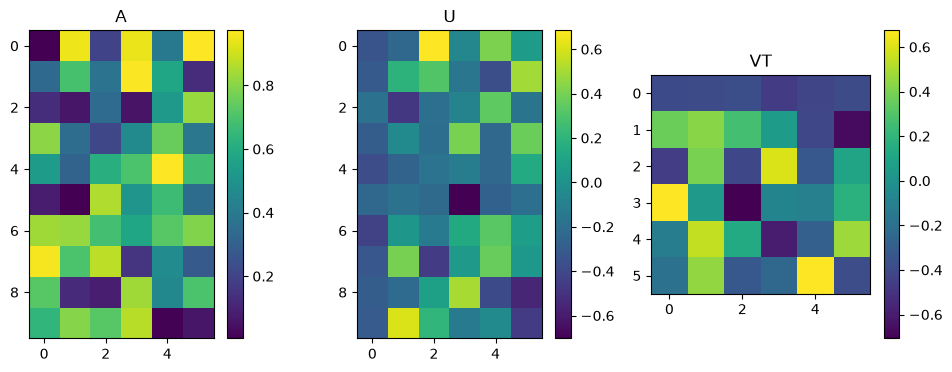

Singular values are:  [4.17896168 1.25539272 1.19620374 0.86082882 0.79916059 0.48156756]


<Figure size 640x480 with 0 Axes>

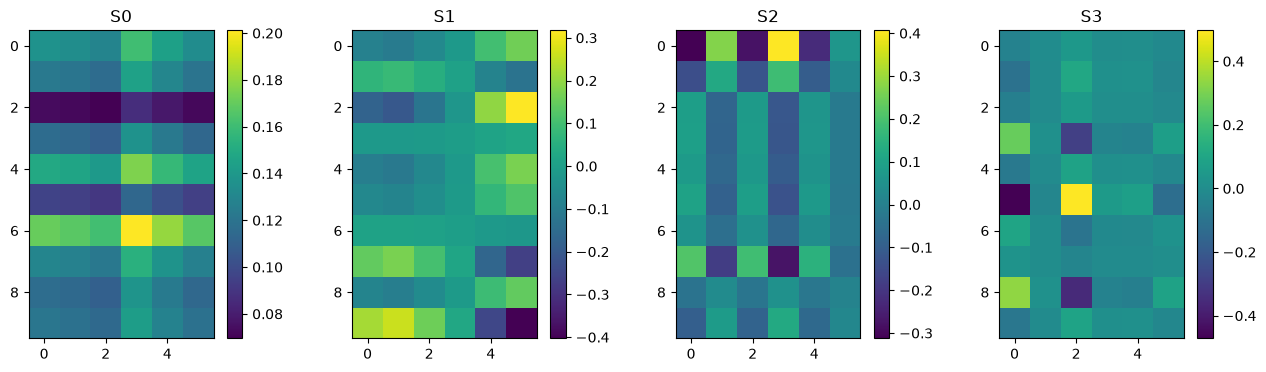

<Figure size 640x480 with 0 Axes>

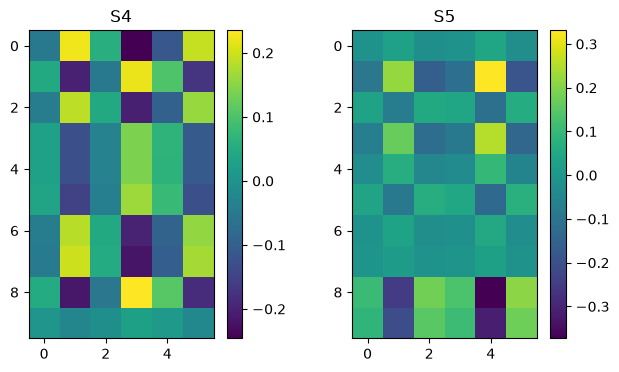

<Figure size 640x480 with 0 Axes>

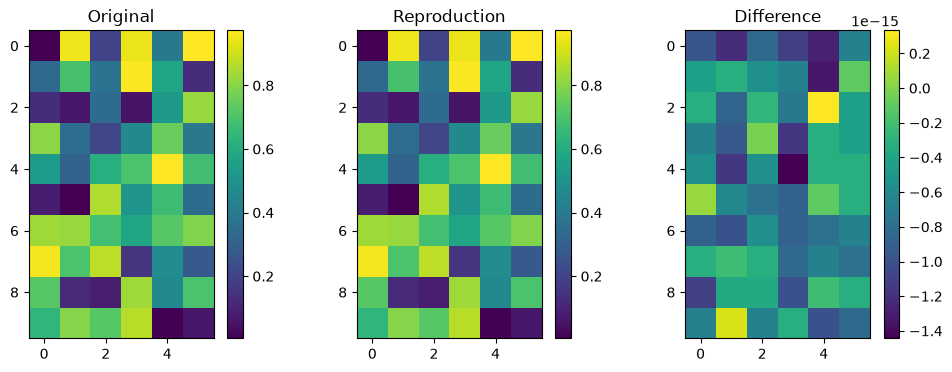

In [6]:
m=10; n=6

A = np.random.rand(m*n).reshape(m,n)

U, Sdiag, VT = np.linalg.svd(A, full_matrices=False)

plot_matrices([A,U,VT], titles=["A", "U","VT"])
print("Singular values are: ", Sdiag)

Ak = np.zeros((n, m, n))

for k in range(n):
    Ak[k] = np.outer(U[:,k], VT[k,:])

plot_matrices(Ak[:],["S%d" % (i,) for i in range(n)])
    
Ar = np.zeros_like(A)
for k in range(n):
    Ar = Ar + Sdiag[k] * Ak[k]

plot_matrices([A, Ar, A-Ar],titles=["Original","Reproduction","Difference"])

<Figure size 640x480 with 0 Axes>

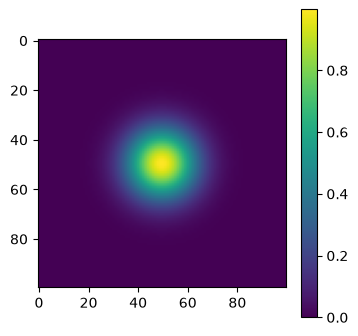

In [12]:
n = 100
x = np.linspace(-5, 5, n)
y = np.linspace(-5, 5, n)
X, Y = np.meshgrid(x, y, indexing='ij')

alpha = 0
A = np.exp(-0.5 * (X**2 + Y**2 + alpha * X * Y))

plot_matrices([A,])

singular values =  [18.1662946   4.86764396  1.30428123  0.34948097  0.09364278] ...


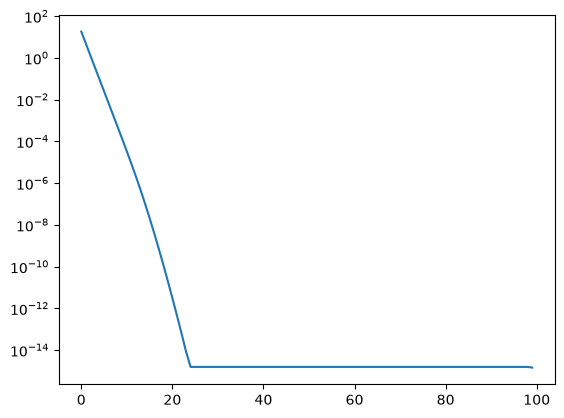

<Figure size 640x480 with 0 Axes>

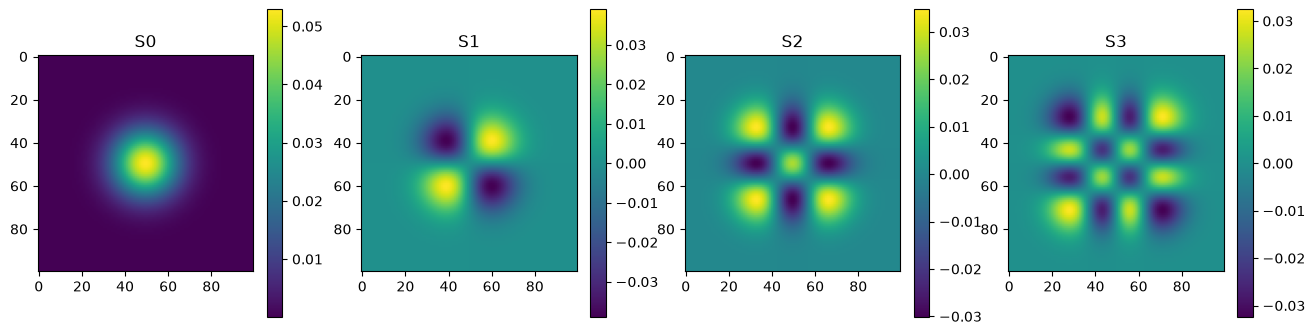

<Figure size 640x480 with 0 Axes>

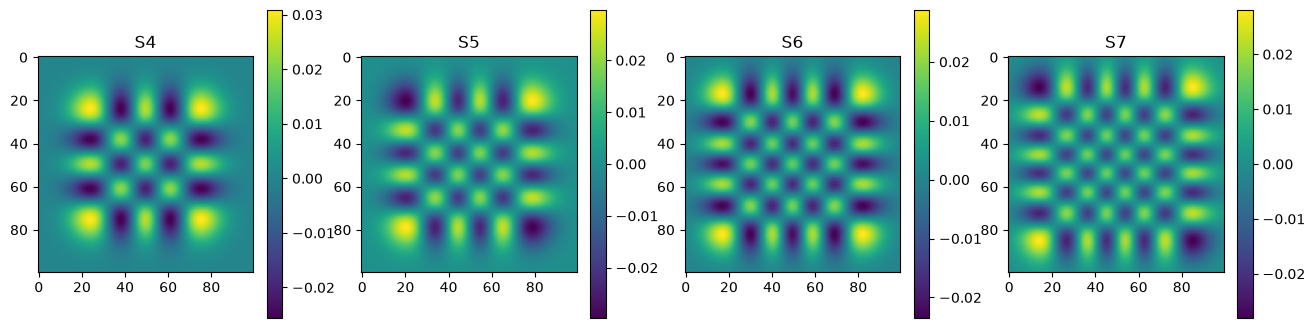

<Figure size 640x480 with 0 Axes>

<Figure size 1600x400 with 0 Axes>

<Figure size 640x480 with 0 Axes>

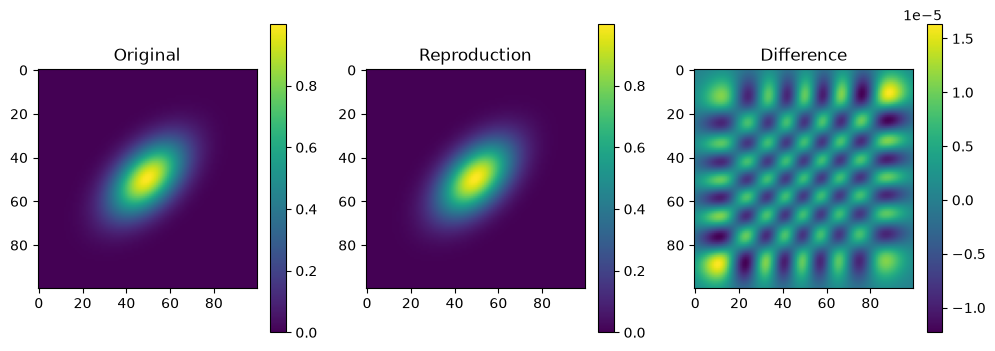

In [13]:
alpha = 1
A = np.exp(-0.5 * (X**2 + Y**2 + alpha * X * Y))

# now do the SVD
U, Sdiag, VT = np.linalg.svd(A, full_matrices=False)

print('singular values = ', Sdiag[:5], '...')

plt.plot(Sdiag)
plt.yscale('log')
plt.show()

# component matrices
m = 8
Ak = np.zeros((m, n, n))
for k in range(m):
    Ak[k] = np.outer(U[:,k], VT[k,:])

plot_matrices(Ak[:],["S%d" % (i,) for i in range(m)])
    
Ar = np.zeros_like(A)
for k in range(m):
    Ar = Ar + Sdiag[k] * Ak[k]

plot_matrices([A, Ar, A-Ar],titles=["Original","Reproduction","Difference"])

## 3. Lorenz equations

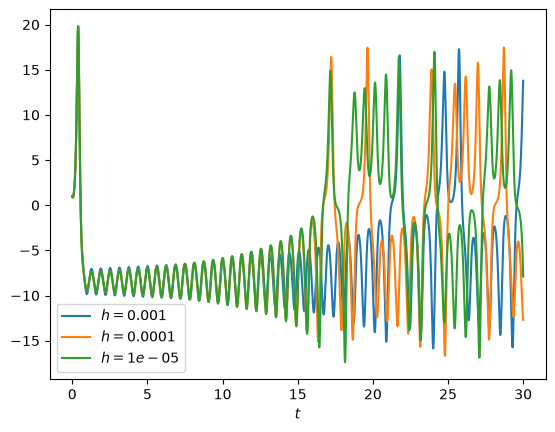

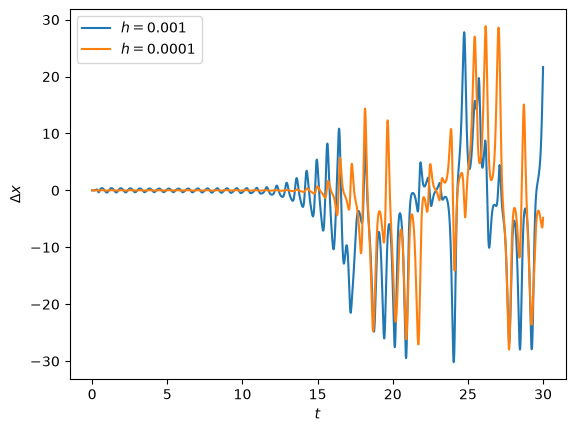

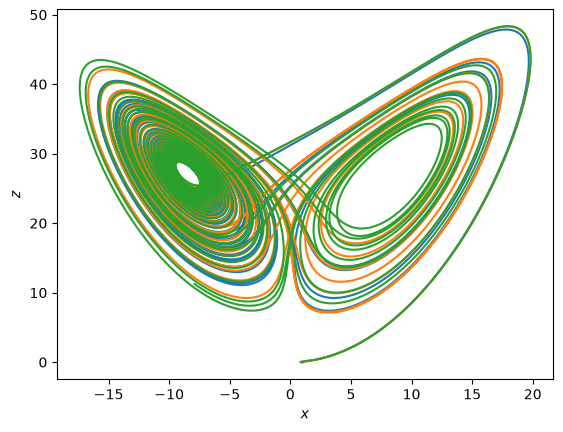

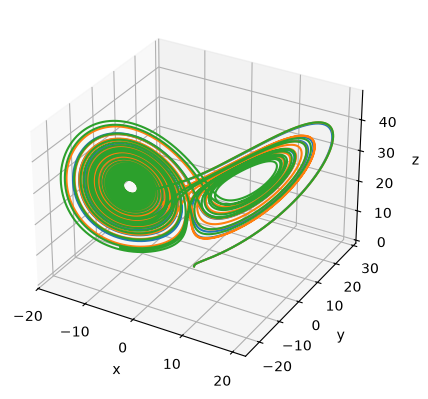

In [8]:
# Lorenz equation parameters
sigma = 10
rho = 28
beta = 8/3

def do_integration(t_end, h, init):
    
    nsteps = int(t_end / h)
    # Newton parameters
    tol = 1e-3
    max_iter = 10

    # Initial conditions
    x = np.zeros(nsteps+1)
    y = np.zeros(nsteps+1)
    z = np.zeros(nsteps+1)

    x[0], y[0], z[0] = init

    for n in range(nsteps):
    
        X = np.array([x[n], y[n], z[n]])

        # Newton iterations
        for k in range(max_iter):

            x1,y1,z1 = X
 
            F = np.array([x1 - x[n] - h*sigma*(y1-x1), 
                         y1 - y[n] - h*(rho*x1 -x1*z1 - y1),
                          z1 - z[n] - h*(x1*y1 - beta*z1)])
            J = np.array([[1+h*sigma,  -h*sigma, 0],[-h*rho+h*z1, 1+h, h*x1], [-h*y1, -h*x1, 1+h*beta]])

            # solve for delta y and update
            delta = np.linalg.solve(J, -F)
            X += delta

            # Check convergence
            if np.linalg.norm(delta) < tol:
                break

        # Store converged solution
        x[n+1] = X[0]
        y[n+1] = X[1]
        z[n+1] = X[2]
    
    t = np.linspace(0, t_end, nsteps+1)

    return t,x,y,z

h1,h2,h3 = 1e-3,1e-4,1e-5
tend = 30

t1,x1,y1,z1 = do_integration(tend, h1, (1,0,0))
t2,x2,y2,z2 = do_integration(tend, h2, (1,0,0))
t3,x3,y3,z3 = do_integration(tend, h3, (1,0,0))

# Plot
plt.plot(t1, x1, label=r'$h=%lg$' % (h1,))
plt.plot(t2, x2, label=r'$h=%lg$' % (h2,))
plt.plot(t3, x3, label=r'$h=%lg$' % (h3,))
plt.xlabel(r'$t$')
plt.legend()
plt.show()

# Plot
plt.figure()
plt.plot(t3, np.interp(t3, t1, x1)-x3, label=r'$h=%lg$' % (h1,))
plt.plot(t3, np.interp(t3, t2, x2)-x3, label=r'$h=%lg$' % (h2,))
plt.ylabel(r'$\Delta x$')
plt.xlabel(r'$t$')
plt.legend()
plt.show()

plt.figure()
plt.plot(x1,z1)
plt.plot(x2,z2)
plt.plot(x3,z3)
plt.ylabel(r'$z$')
plt.xlabel(r'$x$')
plt.show()

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(x1, y1, z1)
ax.plot(x2, y2, z2)
ax.plot(x3, y3, z3)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
plt.show()